# 02 · Cointégration & mean-reversion

**Objectif** : valider statistiquement la mean-reversion — les niveaux sont-ils I(1) ? le spread cointégrant est-il stationnaire ? à quelle vitesse revient-il ?

In [1]:
import sys, warnings
warnings.filterwarnings("ignore")
sys.path.insert(0, "..")
%matplotlib inline
import numpy as np, pandas as pd, matplotlib.pyplot as plt
plt.rcParams["figure.figsize"] = (11, 4)
plt.rcParams["axes.grid"] = True
from src import (data_loader as dl, features as ft, stats_tests as st,
                 hedge_ratio as hr, signal as sig, backtest as bt, metrics as mt,
                 curve as cv, regime as rg, pipeline as pl)
from src.config import StrategyConfig, MARKET_EVENTS, REGIME_SEGMENTS
def events(ax):
    for e in MARKET_EVENTS:
        ax.axvline(pd.Timestamp(e["date"]), color="gray", ls=":", lw=1, alpha=.6)

prices = dl.get_prices('futures')

### ADF — prix ≈ I(1) (à la limite), rendements I(0)
Sans tendance, le Brent rejette de justesse la racine unitaire (p ≈ 0,046) ; avec tendance (`ct`), aucun des deux ne la rejette.

In [2]:
for c in ['wti','brent']:
    print(c, 'niveau          :', st.adf_test(prices[c]))
    print(c, 'niveau+tendance :', st.adf_test(prices[c], regression='ct'))
    print(c, 'rendement       :', st.adf_test(ft.log_returns(prices[c]).dropna()))

wti niveau          : ADF(stat=-2.772, p=0.0624, lag=16) -> NON stationnaire @5%
wti niveau+tendance : ADF(stat=-2.773, p=0.2071, lag=16) -> NON stationnaire @5%
wti rendement       : ADF(stat=-12.199, p=0.0000, lag=24) -> stationnaire @5%


brent niveau          : ADF(stat=-2.893, p=0.0462, lag=30) -> stationnaire @5%
brent niveau+tendance : ADF(stat=-2.895, p=0.1640, lag=30) -> NON stationnaire @5%
brent rendement       : ADF(stat=-10.480, p=0.0000, lag=29) -> stationnaire @5%


### Cointégration Engle-Granger
OLS `Brent = α + β·WTI`, puis ADF sur le résidu + test de cointégration.

Engle-Granger(beta=1.057, coint_p=0.0130) -> cointégrés @5%
ADF résidu: ADF(stat=-3.813, p=0.0028, lag=22) -> stationnaire @5%


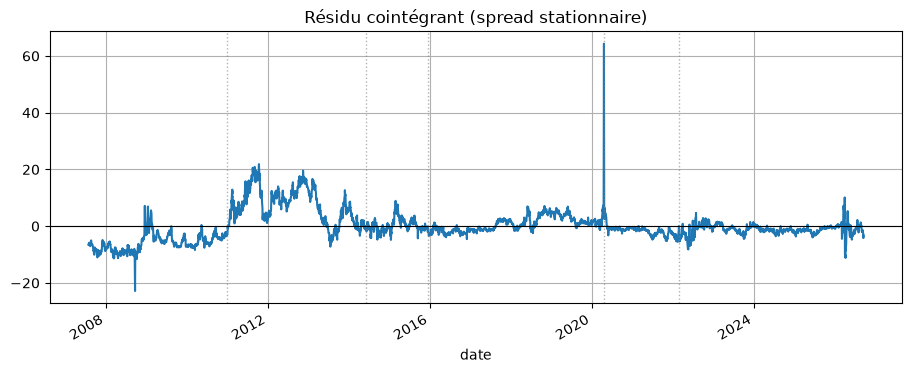

In [3]:
cr = st.engle_granger(prices['brent'], prices['wti'])
print(cr); print('ADF résidu:', cr.adf_resid)
ax = cr.resid.plot(title='Résidu cointégrant (spread stationnaire)'); ax.axhline(0, color='k', lw=.8)
events(ax); plt.show()

### Vitesse de retour à la moyenne
Demi-vie (régression Δspread ~ spread₋₁ ; l'écart est multiplié par ρ = 1+φ chaque jour, d'où demi-vie = −ln2/ln(1+φ)) et exposant de Hurst.

demi-vie = 18.9 jours | Hurst = 0.29 (<0.5 -> mean-reverting)


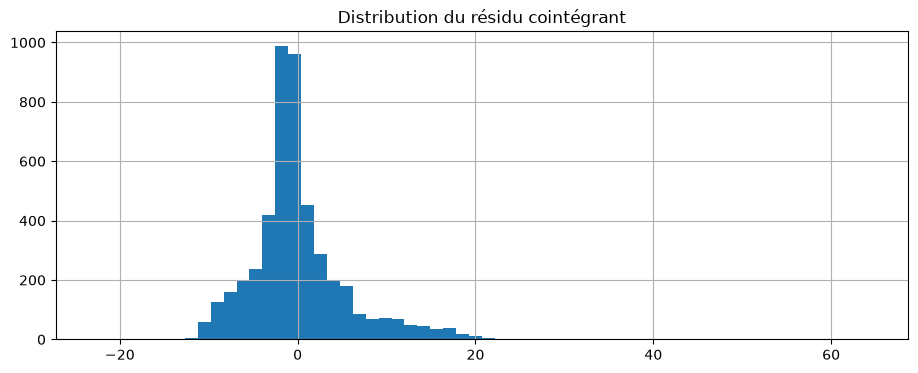

-> lookback z-score fixé à ~2x la demi-vie ~ 40 jours


In [4]:
hl = st.half_life(cr.resid); hu = st.hurst_exponent(cr.resid)
print(f'demi-vie = {hl:.1f} jours | Hurst = {hu:.2f} (<0.5 -> mean-reverting)')
cr.resid.hist(bins=60); plt.title('Distribution du résidu cointégrant'); plt.show()
print('-> lookback z-score fixé à ~2x la demi-vie ~ 40 jours')

### Cointégration glissante — où la relation tient-elle ?

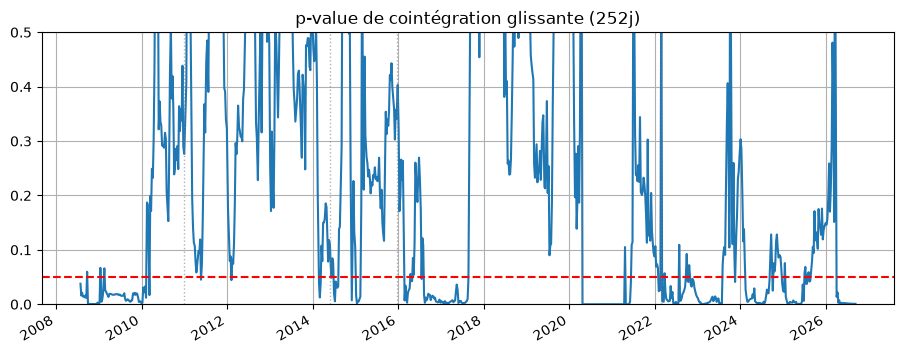

In [5]:
pv = st.rolling_coint_pvalue(prices['brent'], prices['wti'], window=252, step=5)
ax = pv.plot(title='p-value de cointégration glissante (252j)'); ax.axhline(0.05, color='r', ls='--')
events(ax); plt.ylim(0, .5); plt.show()

In [6]:
for a, b in [('2007','2013'), ('2014','2019'), ('2020','2026')]:
    q = prices.loc[a:b]
    print(a, '-', b, ': p =', round(st.engle_granger(q['brent'], q['wti']).coint_pvalue, 3))

2007 - 2013 : p = 0.556
2014 - 2019 : p = 0.003
2020 - 2026 : p = 0.001


**Lecture** : cointégration sur l'ensemble (p = 0,013) mais **pas stable** : non significative sur 2007-2013 (glut de Cushing), nette ensuite — motivant le hedge dynamique et le suivi de régime.